# ST1 Confusion Matrices

Confusion matrices for **Sub-Task 1** of SemEval-2025 Task 9: hazard category (10 classes) and product category (22 classes).

All values are currently **zero placeholders**. To fill them with real results, either:

- **Option A:** set `y_true_*` / `y_pred_*` in Section 3 to your gold and predicted labels, or
- **Option B:** load a CSV with gold and predicted columns (also Section 3).

Then re-run the notebook from the top.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

OUTPUT_DIR = "."       # where the PNG figures are saved
NORMALIZE = False      # True = row-normalised percentages (as in MyMy's figures), False = raw counts
SAVE_FIGURES = True

## 2. ST1 label sets

The official ST1 categories. The order here is the order of rows and columns in the matrices.

In [2]:
HAZARD_CATEGORIES = [
    "allergens",
    "biological",
    "chemical",
    "food additives and flavourings",
    "foreign bodies",
    "fraud",
    "migration",
    "organoleptic aspects",
    "other hazard",
    "packaging defect",
]

PRODUCT_CATEGORIES = [
    "alcoholic beverages",
    "cereals and bakery products",
    "cocoa and cocoa preparations, coffee and tea",
    "confectionery",
    "dietetic foods, food supplements, fortified foods",
    "fats and oils",
    "feed materials",
    "food additives and flavourings",
    "food contact materials",
    "fruits and vegetables",
    "herbs and spices",
    "honey and royal jelly",
    "ices and desserts",
    "meat, egg and dairy products",
    "non-alcoholic beverages",
    "nuts, nut products and seeds",
    "other food product / mixed",
    "pet feed",
    "prepared dishes and snacks",
    "seafood",
    "soups, broths, sauces and condiments",
    "sugars and syrups",
]

print(f"{len(HAZARD_CATEGORIES)} hazard categories, {len(PRODUCT_CATEGORIES)} product categories")

10 hazard categories, 22 product categories


## 3. Data

**Placeholder:** empty label lists, which produce all-zero matrices.

Replace them with your results using one of the options below. Labels must match the names in Section 2 exactly (lowercase).

In [3]:
# --- Placeholder: no predictions yet -> all-zero matrices ---
y_true_hazard, y_pred_hazard = [], []
y_true_product, y_pred_product = [], []

# --- Option A: fill in lists directly ---
# y_true_hazard  = ["biological", "allergens", ...]
# y_pred_hazard  = ["biological", "fraud", ...]
# y_true_product = ["meat, egg and dairy products", ...]
# y_pred_product = ["meat, egg and dairy products", ...]

# --- Option B: load from a CSV file ---
# df = pd.read_csv("st1_predictions.csv")
# y_true_hazard,  y_pred_hazard  = df["hazard-category"],  df["pred_hazard-category"]
# y_true_product, y_pred_product = df["product-category"], df["pred_product-category"]

## 4. Build the confusion matrices

In [4]:
def build_confusion_matrix(y_true, y_pred, labels):
    """Return a labelled confusion matrix (rows = true, columns = predicted).
    With no data, returns an all-zero matrix."""
    if len(y_true) == 0:
        cm = np.zeros((len(labels), len(labels)), dtype=int)
    else:
        unknown = (set(y_true) | set(y_pred)) - set(labels)
        if unknown:
            print(f"Warning: labels not in the label set are ignored: {sorted(unknown)}")
        cm = confusion_matrix(y_true, y_pred, labels=labels)
    return pd.DataFrame(cm, index=labels, columns=labels)


cm_hazard = build_confusion_matrix(y_true_hazard, y_pred_hazard, HAZARD_CATEGORIES)
cm_product = build_confusion_matrix(y_true_product, y_pred_product, PRODUCT_CATEGORIES)

cm_hazard

,allergens,biological,chemical,food additives and flavourings,foreign bodies,fraud,migration,organoleptic aspects,other hazard,packaging defect
allergens,0,0,0,0,0,0,0,0,0,0
biological,0,0,0,0,0,0,0,0,0,0
chemical,0,0,0,0,0,0,0,0,0,0
food additives and flavourings,0,0,0,0,0,0,0,0,0,0
foreign bodies,0,0,0,0,0,0,0,0,0,0
fraud,0,0,0,0,0,0,0,0,0,0
migration,0,0,0,0,0,0,0,0,0,0
organoleptic aspects,0,0,0,0,0,0,0,0,0,0
other hazard,0,0,0,0,0,0,0,0,0,0
packaging defect,0,0,0,0,0,0,0,0,0,0


In [5]:
cm_product

,alcoholic beverages,cereals and bakery products,"cocoa and cocoa preparations, coffee and tea",confectionery,"dietetic foods, food supplements, fortified foods",fats and oils,feed materials,food additives and flavourings,food contact materials,fruits and vegetables,...,ices and desserts,"meat, egg and dairy products",non-alcoholic beverages,"nuts, nut products and seeds",other food product / mixed,pet feed,prepared dishes and snacks,seafood,"soups, broths, sauces and condiments",sugars and syrups
alcoholic beverages,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
cereals and bakery products,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"cocoa and cocoa preparations, coffee and tea",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
confectionery,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"dietetic foods, food supplements, fortified foods",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
fats and oils,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
feed materials,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
food additives and flavourings,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
food contact materials,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
fruits and vegetables,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 5. Plot

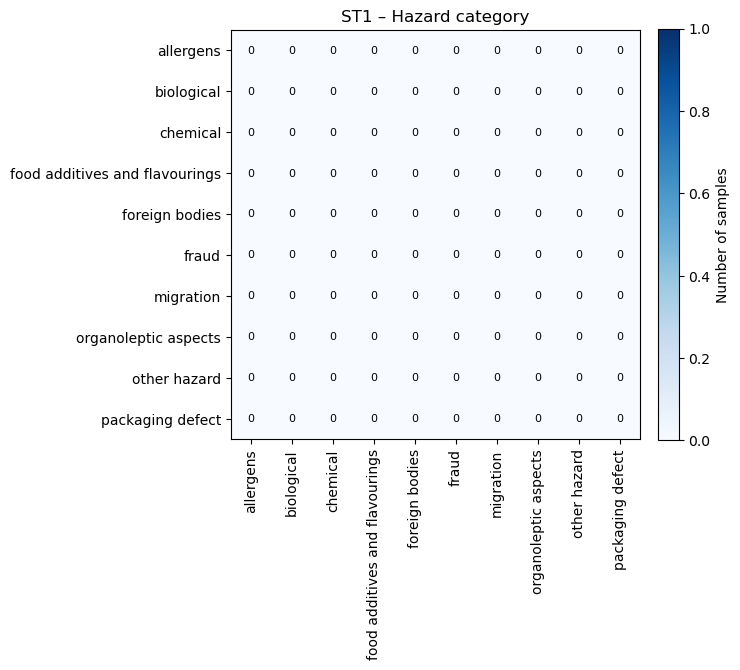

In [7]:
def plot_confusion_matrix(cm, title, normalize=False, filename=None):
    counts = cm.values
    if normalize:
        row_sums = counts.sum(axis=1, keepdims=True)
        values = np.divide(counts, row_sums, out=np.zeros_like(counts, dtype=float), where=row_sums != 0)
        vmax, cbar_label = 1.0, "Row-normalised share"
    else:
        values = counts
        vmax, cbar_label = max(counts.max(), 1), "Number of samples"

    n = len(cm)
    size = max(6, 0.45 * n + 3)
    fig, ax = plt.subplots(figsize=(size, size))
    im = ax.imshow(values, cmap="Blues", vmin=0, vmax=vmax)
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(cbar_label)

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(cm.columns, rotation=90)
    ax.set_yticklabels(cm.index)
    #ax.set_xlabel("Predicted")
    #ax.set_ylabel("True")
    ax.set_title(title)

    # Cell annotations: always show raw counts
    threshold = vmax / 2
    for i in range(n):
        for j in range(n):
            ax.text(j, i, str(counts[i, j]), ha="center", va="center", fontsize=8,
                    color="white" if values[i, j] > threshold else "black")

    fig.tight_layout()
    if filename and SAVE_FIGURES:
        fig.savefig(f"{OUTPUT_DIR}/{filename}", dpi=300, bbox_inches="tight")
    plt.show()


plot_confusion_matrix(cm_hazard, "ST1 – Hazard category", NORMALIZE, "st1_confusion_hazard.png")

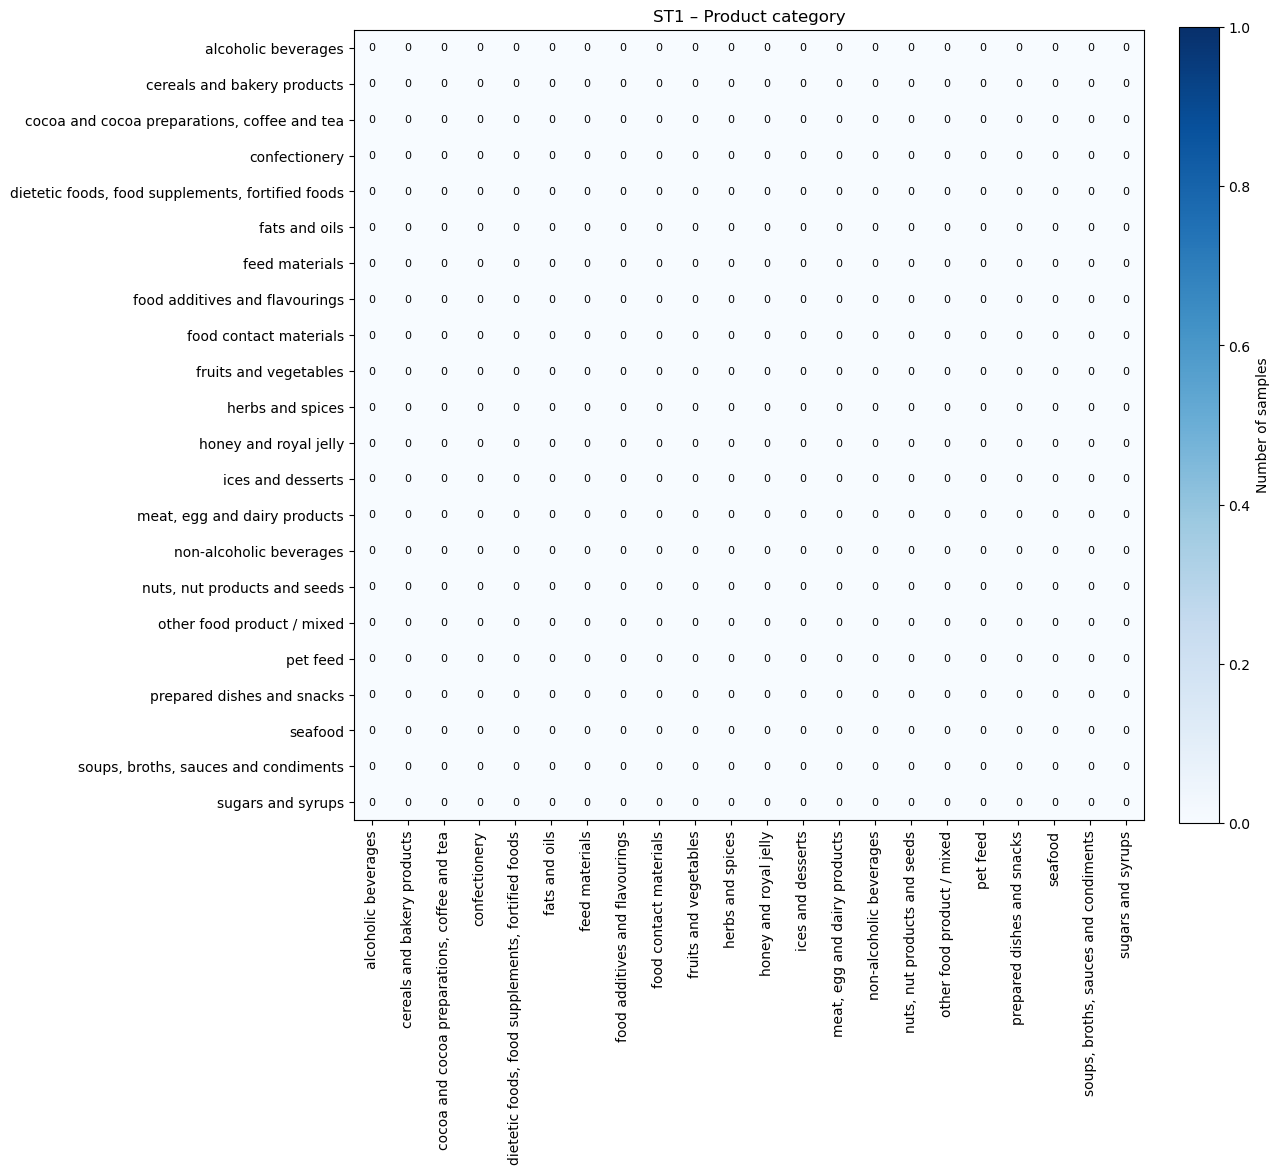

In [8]:
plot_confusion_matrix(cm_product, "ST1 – Product category", NORMALIZE, "st1_confusion_product.png")